## 0. Config & Imports

In [246]:

# How to handle participants who used the website more than once (presumably for mistake or curiosity):
#
#   "max_deliberation_time" -> keep only the row with the highest
#                              deliberation_time for each participant               -> Don't lose any data, but some entry 
#                                                                                       could be mistakely refearred to a condition
#
#   "unique"                -> drop every participant who appears more than once    -> We lose some data(unethical), but we are sure that every 
#                                                                                       entry is correctly referred to a condition

CONFIG_reused_website_cases = "max_deliberation_time"
#CONFIG_reused_website_cases = "unique"

In [247]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import PercentFormatter


In [248]:
webpage_data = pd.read_csv("webpage_data.csv")
questionnaire_data = pd.read_csv("questionnaire_data.csv")

data = pd.merge(webpage_data, questionnaire_data, on="participant_id", how= "inner")

## 1. Data Preparation

Before conducting the statistical analysis, the dataset is inspected and prepared.

The first step consists of checking the dataset structure, changing automatic google sheet column names, cutting useless data and verifying the data types of the variables.

Some auxiliary columns are created using the data we have

In [249]:
data = data.rename(columns={
    "  Which age group do you belong to?   ":"age_group",
    "What are you using for this test?":"device_type",
    "How often do you browse or make purchases on online shopping websites?\"": "purchase_frequency",
    "On average, how many hours per day do you spend using a computer (for work, study, or leisure)?":"computer_usage",
    "How much do you feel the website tried to pressure you into making an account/ subscribe ":"pressure_perception",
    "To what extent did you find the decline option sarcastic or mocking?":"sarcastic_mocking_extent",
    "Did you read the pop up?":"have_read_popup",
    "MENTAL DEMAND":"nasa_mental_demand",
    "TEMPORAL DEMAND":"nasa_temporal_demand",
    "FRUSTRATION LEVEL":"nasa_frustration",
    "PERFORMANCE":"nasa_performance",
    "EFFORT":"nasa_effort",
    "WILLINGNESS TO RECCOMEND":"willingness_to_recommend"
                            })

In [250]:
quantitative_data=data[['timestamp','participant_id','condition','action_taken','deliberation_time_sec','email_entered','checkboxes_checked','is_test','nasa_mental_demand','nasa_temporal_demand','nasa_performance','nasa_effort','nasa_frustration','willingness_to_recommend','age_group','device_type','purchase_frequency','computer_usage','pressure_perception','sarcastic_mocking_extent','have_read_popup']]

In [251]:
acceptance_mapping = {
    "clicked_submit_decline": 0,
    "clicked_submit_accept": 1,
    "clicked_decline_text_link": 0,
    "clicked_close_x_button": 0 #TODO: delete it if we decide to delete pilot testings -> This is not a case anymore
}

quantitative_data["acceptance"] = quantitative_data["action_taken"].map(acceptance_mapping).astype("Int64")

In [252]:
#quantitative_data[quantitative_data["condition"] == "Control"]

### Multiple website usage from the same user
Some particiipant opened the website multiple times, we suppose by mistake or curiosity, 
2 Ways can be implemented to clean those esntries:
 A: Cut the entire participant -> safe data but we lose many tests (also unethical)
 B: We keep only the use with the longest deliberation time -> some questionnaire could be refeared to an unexpected condition
    We also assure that the usage is not refeared to a future discovery of the test by chacking the website usage timestamp with the questionnaire completed timestamp

CHANGE IT IN CONFIG SECTION

In [253]:
if CONFIG_reused_website_cases == "max_deliberation_time":
    quantitative_data = quantitative_data[quantitative_data['deliberation_time_sec'] == quantitative_data.groupby('participant_id')['deliberation_time_sec'].transform('max')]
elif CONFIG_reused_website_cases == "unique":
    quantitative_data = quantitative_data[~quantitative_data.duplicated(subset='participant_id', keep=False)]

# 2. Quick overview on data

In [254]:
quantitative_data.info()

<class 'pandas.DataFrame'>
Index: 20 entries, 0 to 35
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   timestamp                 20 non-null     str    
 1   participant_id            20 non-null     str    
 2   condition                 20 non-null     str    
 3   action_taken              20 non-null     str    
 4   deliberation_time_sec     20 non-null     float64
 5   email_entered             20 non-null     bool   
 6   checkboxes_checked        20 non-null     str    
 7   is_test                   0 non-null      str    
 8   nasa_mental_demand        16 non-null     float64
 9   nasa_temporal_demand      16 non-null     float64
 10  nasa_performance          2 non-null      float64
 11  nasa_effort               15 non-null     float64
 12  nasa_frustration          16 non-null     float64
 13  willingness_to_recommend  16 non-null     float64
 14  age_group                 18

In [255]:
quantitative_data.head()

,timestamp,participant_id,condition,action_taken,deliberation_time_sec,email_entered,checkboxes_checked,is_test,nasa_mental_demand,nasa_temporal_demand,...,nasa_frustration,willingness_to_recommend,age_group,device_type,purchase_frequency,computer_usage,pressure_perception,sarcastic_mocking_extent,have_read_popup,acceptance
0,2026-11-11T10:29:59.876Z,P_9FKETYLM,v1_condition,clicked_close_x_button,3.80,False,none,NaN,1.0,1.0,...,1.0,4.0,22-26,Smartphone,A couple of times per month,More than 8 hours,4.0,1.0,NaN,0
1,2026-11-11T13:28:59.899Z,P_8S0L2MHA,v2_condition,clicked_decline_text_link,2.01,False,2/2 checked,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5.0,3.0,Yes,0
2,2026-11-11T13:33:20.565Z,P_CMQ6YXJ9,v1_condition,clicked_submit_decline,3.28,False,none,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,4.0,1.0,Yes,0
3,2026-11-12T16:24:09.035Z,P_BQ2TDYO7,v1_condition,clicked_submit_decline,2.17,False,none,NaN,NaN,NaN,...,NaN,NaN,18-21,Computer / Laptop,Less than once per month,More than 8 hours,NaN,NaN,No,0
4,2026-11-12T16:28:57.013Z,P_IJFECCH8,v3_condition,clicked_submit_accept,54.11,True,none,NaN,8.0,3.0,...,6.0,4.0,18-21,Smartphone,A couple of times per month,More than 8 hours,5.0,6.0,Yes,1


condition
v1_condition    9
v2_condition    5
v3_condition    6
Name: count, dtype: int64

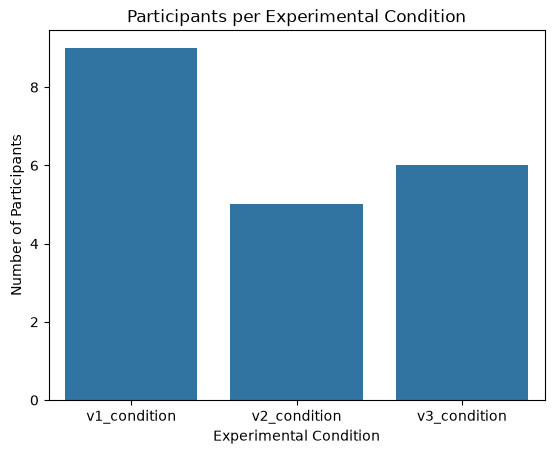

In [256]:
condition_counts = quantitative_data["condition"].value_counts().sort_index()

display(condition_counts)

sns.countplot(data=quantitative_data, x="condition", order=["v1_condition", "v2_condition", "v3_condition"])

plt.title("Participants per Experimental Condition")
plt.xlabel("Experimental Condition")
plt.ylabel("Number of Participants")
plt.show()

### Participant Overview

This section provides a descriptive overview of the participants involved in the experiment.

The analysis considers the number of participants in each experimental condition, together with demographic and behavioural characteristics such as:

- Age group
- Device used during the experiment
- Online shopping frequency
- Daily computer usage

The purpose is to understand the composition of the sample and identify potential differences between experimental groups.

Since the sample is relatively small, these characteristics are primarily used for descriptive purposes rather than drawing conclusions about the general population.

In [257]:
profile_columns = [
    "age_group",
    "device_type",
    "purchase_frequency",
    "computer_usage"
]

for column in profile_columns:

    print(f"\n--- {column} ---")

    display(
        pd.crosstab(
            quantitative_data["condition"],
            quantitative_data[column],
            margins=True
        )
    )


--- age_group ---


age_group,18-21,22-26,27-32,All
condition,,,,
v1_condition,1,5,2,8
v2_condition,0,3,1,4
v3_condition,1,4,1,6
All,2,12,4,18



--- device_type ---


device_type,Computer / Laptop,Smartphone,All
condition,,,
v1_condition,2,6,8
v2_condition,0,4,4
v3_condition,1,5,6
All,3,15,18



--- purchase_frequency ---


purchase_frequency,A couple of times per month,Less than once per month,Multiple times per week,All
condition,,,,
v1_condition,2,5,1,8
v2_condition,1,3,0,4
v3_condition,3,2,1,6
All,6,10,2,18



--- computer_usage ---


computer_usage,2-4 hours,5-8 hours,More than 8 hours,All
condition,,,,
v1_condition,1,3,4,8
v2_condition,1,2,1,4
v3_condition,1,2,3,6
All,3,7,8,18


# 3. Data Analysis

## Research Question:
To what extent does cognitive workload (specifically NASA-
TLX mental demand, temporal demand, and frustration) mediate the relationship
between confirmshaming interface design and immediate promotional offer
acceptance (task compliance) in e-commerce checkout flows?

### 3.1 Acceptance Rate between conditions

The study considers three interface conditions:

- **V1 – Control condition:** A clean interface without deceptive patterns.
- **V2 – Confirmshaming condition:** An interface using emotionally manipulative language to discourage users from declining a promotional offer.
- **V3 – Preselected options condition:** An interface where certain options are preselected by default.

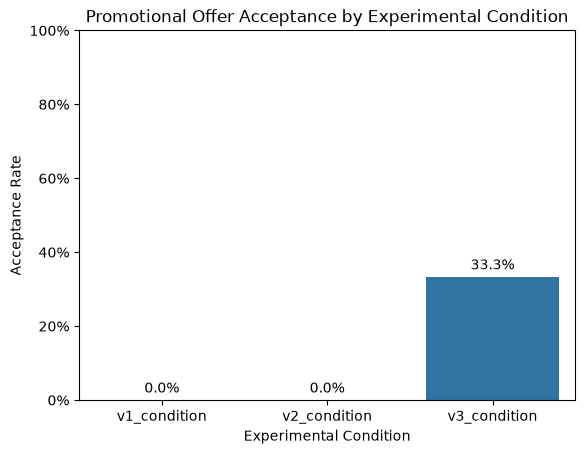

In [ ]:
overview = (
    quantitative_data.groupby("condition")
    .agg(
        participants=("participant_id", "nunique"),
        accepted=("acceptance", "sum"),
        valid_responses=("acceptance", "count")
    )
)

overview["not_accepted"] = (
    overview["valid_responses"] - overview["accepted"]
)

overview["acceptance_rate"] = (
    overview["accepted"] / overview["valid_responses"] * 100
)

plot = sns.barplot(
    data=quantitative_data,
    x="condition",
    y="acceptance",
    errorbar=None
)

# values on top of the bars, formatted as percentages
for container in plot.containers:
    plot.bar_label(container, labels=[f"{v.get_height():.1%}" for v in container], padding=3)
#formats 0-1 range to percentage on y-axis (e.g. 0.5 -> 50%)
plot.yaxis.set_major_formatter(PercentFormatter(xmax=1)) 

plt.title("Promotional Offer Acceptance by Experimental Condition")
plt.xlabel("Experimental Condition")
plt.ylabel("Acceptance Rate")
plt.ylim(0, 1)

plt.show()